In [1]:
import pandas as pd 
import numpy as np 
import polars as pl
from typing import List
from collections import Counter
import glob, os

import matplotlib.pyplot as plt
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats("retina")
from matplotlib.ticker import FuncFormatter
import matplotlib as mpl
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans", "sans-serif"],
    "font.size": 12,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
})


import yaml
with open("../../src/configs.yml", "r") as configs:
    configs = yaml.safe_load(configs)

DATAPATH = configs["SERVER_DATA"]
ROOTPATH = configs["SERVER_WD"]

## load data
### activities around banned subreddits

In [ ]:
from src.utils.data_loader_polars import load_filtered_data

# analysis window
years = range(2005, 2020)

# load banned subreddits
sets_df = pd.read_csv("../../data-public/subreddit_sets.csv")
subreddit_sets = {
    name: set(group["subreddit"])
    for name, group in sets_df.groupby("set")
}
banned_subreddits = subreddit_sets["banned"]

# load data of banned subreddits / users
def load_post_subreddit(subm_input_fpath, comm_input_fpath, subrs=[], years=years):
    cols = ["id","author","subreddit","created_utc"]
    subm_df = load_filtered_data(years=years, data_dir=subm_input_fpath, filetype="submissions",filter_bots=False).select(cols)
    comm_df = load_filtered_data(years=years, data_dir=comm_input_fpath, filetype="comments",filter_bots=False).select(cols)
    subm_df = subm_df.with_columns(pl.lit("submission").alias("kind"))
    comm_df = comm_df.with_columns(pl.lit("comment").alias("kind"))
    post_df = pl.concat([subm_df, comm_df], how="vertical")
    if len(subrs) > 0:
        post_df = post_df.filter(pl.col("subreddit").is_in(subrs))
    return post_df

# submissions and comments by banned subreddits' users
subm_banned_user = f"{DATAPATH}/filtered-data-new/submissions/subm-from-user-banned-2020-subset3274-lite/" 
comm_banned_user = f"{DATAPATH}/filtered-data-new/comments/comm-from-user-banned-2020-subset3274-lite/" 

post_banned_user = load_post_subreddit(subm_banned_user, comm_banned_user)

# submissions and comments within banned subreddits
post_banned = post_banned_user.filter(pl.col("subreddit").is_in(banned_subreddits))

Banned subreddits: 3,274
******************
Loading Submissions from /cinddata/reddit-ban-study/filtered-data-new/submissions/subm-from-user-banned-2020-subset3274-lite/...
	loading: 2005
	loading: 2006
	loading: 2007
	loading: 2008
	loading: 2009
	loading: 2010
	loading: 2011
	loading: 2012
	loading: 2013
	loading: 2014
	loading: 2015
	loading: 2016
	loading: 2017
	loading: 2018
	loading: 2019
******************
Loading Comments from /cinddata/reddit-ban-study/filtered-data-new/comments/comm-from-user-banned-2020-subset3274-lite/...
	loading: 2005
	loading: 2006
	loading: 2007
	loading: 2008
	loading: 2009
	loading: 2010
	loading: 2011
	loading: 2012
	loading: 2013
	loading: 2014
	loading: 2015
	loading: 2016
	loading: 2017
	loading: 2018
	loading: 2019


### toxicity scores inside/outside banned subreddits

In [3]:
# toxicity for submissions within banned subreddits
toxicity_output_dir = f"{DATAPATH}/output/toxicity/subset3274/detoxify-multilingual-all-subm-perweek/"
inside_scores = (
    pl.scan_parquet(f"{toxicity_output_dir}subm-comm-from-subr-banned-2020-by-subm-toxicity.parquet")
    .select(["id", "toxicity"])
    .filter(pl.col("toxicity").is_not_null())
    .unique("id")
)

inside_meta = (
    pl.scan_parquet(f"{DATAPATH}/filtered-data-new/submissions/subm-from-subr-banned-2020-subset3274/*.parquet")
    .select(["id", "author", "subreddit", "created_utc"])
    .filter(pl.col("subreddit").is_in(list(banned_subreddits)))
    .unique("id")
)
inside_subm_author = set(inside_meta.collect()["author"].unique().to_list())
# sanity check: these two dfs should have the same length
print(post_banned.filter(pl.col("kind")=="submission").shape[0])
print(inside_meta.filter(~pl.col("author").is_in(["[deleted]",""])).collect().shape[0])

inside_lf = (
    inside_scores
    .join(inside_meta.lazy(),on="id",how="inner",validate="1:1")
    .with_columns([pl.col("created_utc").cast(pl.Datetime), pl.lit("inside").alias("context")])
)

# toxicity for submissions outside of banned subreddits 
# (created by users who were once active in banned subreddits)

outside_score_dir = f"{DATAPATH}/output/toxicity/subset3274/detoxify-multilingual-all-subm-perweek/subm-comm-from-subm-by-user-banned-2020-subset3274-neighbors-only/"
outside_scores = (
    pl.scan_parquet(f"{outside_score_dir}/*-toxicity.parquet")
    .select(["id", "toxicity"])
    .filter(pl.col("toxicity").is_not_null())
    .unique("id")
)

outside_meta = (
    pl.scan_parquet(f"{DATAPATH}/filtered-data-new/submissions/subm-from-subm-by-user-banned-2020-subset3274-neighbors-only/*.parquet")
    .select(["id", "author", "subreddit", "created_utc",])
    .unique("id")
)
outside_subm_author = set(outside_meta.collect()["author"].unique().to_list())

outside_lf = (
    outside_scores
    .join(outside_meta.lazy(), on="id", how="inner", validate="1:1")
    .with_columns([pl.col("created_utc").cast(pl.Datetime), pl.lit("outside").alias("context")])
)

6830321
6830321


In [4]:
# combine inside/outside dataset
comparison_authors = inside_subm_author & outside_subm_author
INVALID_AUTHORS = ["", "[deleted]",]

context_lf = (
    pl.concat([inside_lf, outside_lf], how="vertical_relaxed")
    .with_columns([
        pl.col("created_utc").cast(pl.Datetime),
        pl.col("author").cast(pl.Utf8).str.strip_chars(),
        pl.col("toxicity").cast(pl.Float64),
    ])
    .filter(
        pl.col("created_utc").is_not_null()
        & pl.col("author").is_not_null()
        & pl.col("author").is_in(comparison_authors)
        & ~pl.col("author").is_in(INVALID_AUTHORS)
        & pl.col("toxicity").is_not_null()
        & pl.col("toxicity").is_finite()
    )
)

context_df = context_lf.collect()

# descriptives 
descriptives = (
    context_df
    .group_by("context")
    .agg([
        pl.len().alias("n_submissions"),
        pl.col("id").n_unique().alias("n_unique_ids"),
        pl.col("author").n_unique().alias("n_users"),
        pl.col("subreddit").n_unique().alias("n_subreddits"),
        pl.col("created_utc").min().alias("min_date"),
        pl.col("created_utc").max().alias("max_date"),
        pl.col("toxicity").mean().alias("mean_toxicity"),
    ])
    .sort("context")
)

descriptives

context,n_submissions,n_unique_ids,n_users,n_subreddits,min_date,max_date,mean_toxicity
str,u32,u32,u32,u32,datetime[μs],datetime[μs],f64
"""inside""",6306940,6306940,542708,3231,2006-02-22 07:42:02,2019-12-31 23:59:47,0.324899
"""outside""",65048689,65048689,542708,412429,2005-06-23 18:45:14,2019-12-31 23:59:59,0.186486


In [5]:
# prepare dataframe for user activity thresholding
user_activity_df = (
    post_banned
    .group_by("author")
    .agg([
        pl.col("id").count().alias("n_posts"),
        pl.col("created_utc").min().alias("first_post_date"),
        pl.col("created_utc").max().alias("last_post_date")
    ])
    .with_columns(((pl.col("last_post_date") - pl.col("first_post_date")).dt.total_days()+1).alias("active_days"))
)

user_activity_df

author,n_posts,first_post_date,last_post_date,active_days
str,u32,datetime[ms],datetime[ms],i64
"""neyen""",87,2016-08-29 05:43:46,2019-09-25 02:55:02,1122
"""InadequateThought""",3,2018-05-24 18:52:03,2018-06-28 22:02:43,36
"""masterct""",1,2018-03-27 16:53:52,2018-03-27 16:53:52,1
"""haise_the_crossbreed""",1,2016-06-23 02:20:10,2016-06-23 02:20:10,1
"""Sindorein""",1,2016-11-09 06:59:16,2016-11-09 06:59:16,1
…,…,…,…,…
"""jrue3""",1,2016-05-15 03:41:16,2016-05-15 03:41:16,1
"""TisTheWindAndNothing""",1,2017-05-20 05:18:56,2017-05-20 05:18:56,1
"""WolfRamHart""",1,2014-06-29 14:43:27,2014-06-29 14:43:27,1


## staggered DID

In [6]:
import statsmodels.formula.api as smf

OUTCOME = "all"  # "outside" or "all"
# OUTCOME = "outside"  # "outside" or "all"

# PARAMETER M
PRE_MONTHS = 6
POST_MONTHS = 6

# sustained-engagement treatment definition
ACTIVITY_THRESHOLD = 20       # K: banned-subreddit submissions + comments
QUALIFICATION_MONTHS = 3      # L: K activities must occur within this many months
# for first-entry: K = 1, L = 1
# main text output: K = 20, L = 3
# ROBUSTNESS CHECKS:
# K = 10, 40
# L = 2, 4

# g = the END of the first qualifying sustained-engagement window.
#
# qualification: g-L+1, ..., g
# pre:           g-L-M+1, ..., g-L   (M = PRE_MONTHS)
# post:          g+1, ..., g+M       (M = POST_MONTHS)
#
# keep this at 1 so the qualification-ending month g is excluded.
POST_START_LAG = 1

# start permissively. Increase these in sensitivity checks.
MIN_SUBMISSIONS_PER_WINDOW = 5
MIN_ACTIVE_MONTHS_PER_WINDOW = 3

# drop very small cohort comparisons.
MIN_TREATED_PER_COHORT = 10
MIN_CONTROLS_PER_COHORT = 10

INVALID_AUTHORS = ["", "[deleted]", "AutoModerator"]

In [7]:
# define treatment as the first sustained-engagement episode
# Treatment occurs in the first month g for which the user has at least K
# banned-subreddit activities within the trailing L calendar months:
# g-L+1, ..., g.
#
# We keep the variable name `first_entry` only to minimize downstream edits;
# it now means first sustained-engagement treatment, NOT first banned-subreddit entry.

monthly_banned_activity = (
    post_banned
    .with_columns([
        pl.col("created_utc").cast(pl.Datetime),
        pl.col("author").cast(pl.Utf8).str.strip_chars(),
        (pl.col("created_utc").dt.year() * 12 + pl.col("created_utc").dt.month() - 1)
        .cast(pl.Int32).alias("activity_month_idx"),
    ])
    .group_by(["author", "activity_month_idx"])
    .agg(pl.len().alias("n_banned_activities"))
)

# Each month's activity contributes to each possible qualification-ending
# month in which it falls inside the trailing L-month window.
qualifying_months = (
    monthly_banned_activity
    .with_columns(
        pl.int_ranges(
            pl.col("activity_month_idx"),
            pl.col("activity_month_idx") + QUALIFICATION_MONTHS,
        ).alias("cohort_idx")
    )
    .explode("cohort_idx")
    .group_by(["author", "cohort_idx"])
    .agg(
        pl.col("n_banned_activities")
        .sum()
        .alias("n_activities_qualification_window")
    )
    .filter(
        pl.col("n_activities_qualification_window") >= ACTIVITY_THRESHOLD
    )
)

first_entry = (
    qualifying_months
    .group_by("author")
    .agg(
        pl.col("cohort_idx").min().alias("cohort_idx")
    )
)

first_entry.head()


author,cohort_idx
str,i64
"""throwitaway7222""",24226
"""lesserlife7""",24193
"""DeputyDelicious""",24194
"""tprocroi""",24201
"""shrubmunch""",24228


In [ ]:
# prepare toxicity dataframe for analysis
toxicity_base = context_df.select(["id", "author", "created_utc", "toxicity", "context"])

if OUTCOME == "outside":
    toxicity_base = toxicity_base.filter(pl.col("context") == "outside")
elif OUTCOME == "all":
    pass
else:
    raise ValueError("OUTCOME must be either 'outside' or 'all'.")


# use a LEFT join so users who never reach the sustained-engagement
# threshold remain available for the robustness specification.
toxicity_base_all = (
    toxicity_base
    .with_columns([
        pl.col("created_utc").dt.truncate("1mo").alias("month"),
        (pl.col("created_utc").dt.year() * 12 + pl.col("created_utc").dt.month() - 1)
        .cast(pl.Int32).alias("month_idx"),
    ])
    .join(
        first_entry.select(["author", "cohort_idx"]),
        on="author", how="left", validate="m:1",
    )
)

# main specification is unchanged substantively:
# keep only users who eventually reach the sustained-engagement threshold.
toxicity_base = (
    toxicity_base_all
    .filter(pl.col("cohort_idx").is_not_null())
)

toxicity_base


id,author,created_utc,toxicity,context,month,month_idx,cohort_idx
str,str,datetime[μs],f64,str,datetime[μs],i32,i64
"""5a42yl""","""theartilleryshow""",2016-10-30 02:34:24,0.11615,"""inside""",2016-10-01 00:00:00,24201,24201
"""7xreh8""","""nklotz""",2018-02-15 16:16:33,0.080627,"""inside""",2018-02-01 00:00:00,24217,24209
"""b8cqgq""","""radfemscientist""",2019-04-02 01:42:12,0.008377,"""inside""",2019-04-01 00:00:00,24231,24230
"""9p0uw0""","""watango""",2018-10-17 17:40:43,0.000596,"""inside""",2018-10-01 00:00:00,24225,24204
"""8ehqbg""","""Bacontastegood""",2018-04-24 04:16:14,0.890625,"""inside""",2018-04-01 00:00:00,24219,24212
…,…,…,…,…,…,…,…
"""9j0zz0""","""AutoModerator""",2018-09-26 09:35:45,0.000408,"""outside""",2018-09-01 00:00:00,24224,24174
"""ash0ej""","""peterboykin""",2019-02-19 23:34:05,0.000744,"""outside""",2019-02-01 00:00:00,24229,24203
"""9hxpfu""","""riotingmashedpotato""",2018-09-22 06:43:35,0.001484,"""outside""",2018-09-01 00:00:00,24224,24229


In [ ]:
# cohorts with complete calendar support
min_observed_month = toxicity_base.select(pl.col("month_idx").min()).item()
max_observed_month = toxicity_base.select(pl.col("month_idx").max()).item()

last_post_offset = (POST_START_LAG + POST_MONTHS - 1)

valid_cohort_ids = (
    first_entry
    .filter(
        # the pre-period must finish BEFORE the L-month
        # qualification window begins.
        (
            pl.col("cohort_idx")
            >= min_observed_month + PRE_MONTHS + QUALIFICATION_MONTHS - 1
        )
        & (pl.col("cohort_idx") <= max_observed_month - last_post_offset)
    )
    .select("cohort_idx")
    .unique()
    .sort("cohort_idx")
    .get_column("cohort_idx")
    .to_list()
)

print(
    "Calendar-supported cohorts:",
    len(valid_cohort_ids),
)


Calendar-supported cohorts: 134


\
**Assign observations to cohort-specific stacks**

Treatment is the first sustained-engagement episode: the first month $g$ in which a user accumulates at least $K$ activities in later-banned subreddits within the trailing $L$-month window.

For a user treated in cohort$(g$:

$$
\text{qualification}: \quad g-L+1,\ldots,g
$$

To keep the baseline outside this qualification period:

$$
\text{pre}: \quad g-L-M+1,\ldots,g-L
$$

and:

$$
\text{post}: \quad g+1,\ldots,g+M.
$$

With the current specification $L=3$ and $M=6$:

$$
\text{pre}: g-8,\ldots,g-3,\qquad \\
\text{qualification}: g-2,\ldots,g,\qquad \\ 
\text{post}: g+1,\ldots,g+6.
$$

For an observation in month $m$, pre-period assignment therefore requires:

$$
m+L \leq g \leq m+L+M-1,
$$

whereas post-period assignment requires:

$$
m-M \leq g \leq m-1.
$$

`int_ranges` followed by `explode` copies each observation into every cohort-specific stack for which it belongs to the relevant pre- or post-period. Observations in the focal cohort's qualification period are assigned to neither outcome window.


In [10]:
# assign observations to cohort-specific windows
toxicity_lf = toxicity_base.lazy()

# ------------------------------------------------------------
# Pre window
# for cohort g, qualification is g-L+1, ..., g;
# therefore pre is g-L-PRE_MONTHS+1, ..., g-L.
# ------------------------------------------------------------

pre_observations = (
    toxicity_lf
    .with_columns(
        pl.int_ranges(
            pl.col("month_idx") + QUALIFICATION_MONTHS,
            pl.col("month_idx") + QUALIFICATION_MONTHS + PRE_MONTHS,
        ).alias("stack_cohort")
    )
    .explode("stack_cohort")
    .with_columns(pl.lit("pre").alias("period"))
)


# ------------------------------------------------------------
# Post window:
# g+1, ..., g+POST_MONTHS when POST_START_LAG = 1
# ------------------------------------------------------------

post_observations = (
    toxicity_lf
    .with_columns(
        pl.int_ranges(
            pl.col("month_idx") - (POST_START_LAG + POST_MONTHS - 1),
            pl.col("month_idx") - POST_START_LAG + 1,
        ).alias("stack_cohort")
    )
    .explode("stack_cohort")
    .with_columns(pl.lit("post").alias("period"))
)


stacked_observations = (
    pl.concat([pre_observations, post_observations], how="vertical_relaxed")

    # retain only actual treatment cohorts with complete support.
    .filter(pl.col("stack_cohort").is_in(valid_cohort_ids))

    # a user is treated in stack g if sustained engagement is first reached in g.
    .with_columns((pl.col("cohort_idx") == pl.col("stack_cohort")).alias("treated"))

    # keep:
    # 1. users treated in this cohort; or
    # 2. users whose OWN qualification window begins only after this stack's post window ends.
    #
    # the + QUALIFICATION_MONTHS - 1 buffer prevents
    # controls from already being inside their later qualification window.
    .filter(
        pl.col("treated")
        | (
            pl.col("cohort_idx")
            > pl.col("stack_cohort") + last_post_offset + QUALIFICATION_MONTHS - 1
        )
    )
)


\
**Main control definition: later-treated users**

For the main specification, controls are users who eventually reach the same sustained-engagement threshold, but sufficiently later that their own $L$-month qualification period has not begun during the focal cohort's post-treatment window.

Because $G_i$ denotes the **end** of user $i$'s qualification period, the user's qualification period begins at $G_i-L+1$. Therefore a control for cohort $g$ must satisfy:

$$
G_i-L+1 > g+M,
$$

or equivalently:

$$
G_i > g+M+L-1.
$$

With $M=6$ and $L=3$:

$$
G_i > g+8.
$$

Thus, the main specification compares users reaching sustained engagement in month \(g\) with users who will also reach sustained engagement, but whose own qualification period begins only after the focal post-treatment window ends.

Users who never reach the sustained-engagement threshold are excluded from this **main** specification. A robustness specification below adds these observed never-treated but banned-community-exposed users to the control pool.


In [11]:
# user-level six-month window averages

user_window_toxicity = (
    stacked_observations
    .group_by(["author", "stack_cohort", "treated", "period"])
    .agg([
        pl.col("toxicity").mean().alias("window_toxicity"),
        pl.len().alias("n_scored_submissions"),
        pl.col("month_idx").n_unique().alias("n_active_months"),
    ])
    .collect()
)

user_window_toxicity.head()

author,stack_cohort,treated,period,window_toxicity,n_scored_submissions,n_active_months
str,i64,bool,str,f64,u32,u32
"""mellis5""",24224,false,"""post""",0.000416,1,1
"""Mr_Biggums""",24195,false,"""pre""",0.341134,7,6
"""oreganoooo""",24183,false,"""pre""",0.328721,3,3
"""Chesterlespaul""",24170,false,"""pre""",0.00421,4,4
"""fabbbyyyyyUAS""",24197,false,"""pre""",0.023158,16,5


In [12]:
pre_window = (
    user_window_toxicity
    .filter(pl.col("period") == "pre")
    .select([
        "author",
        "stack_cohort",
        "treated",
        pl.col("window_toxicity").alias("pre_toxicity"),
        pl.col("n_scored_submissions").alias("n_pre_submissions"),
        pl.col("n_active_months").alias("n_pre_active_months"),
    ])
)


post_window = (
    user_window_toxicity
    .filter(pl.col("period") == "post")
    .select([
        "author",
        "stack_cohort",
        "treated",
        pl.col("window_toxicity").alias("post_toxicity"),
        pl.col("n_scored_submissions").alias("n_post_submissions"),
        pl.col("n_active_months").alias("n_post_active_months"),
    ])
)

# paired pre/post observations
did_pairs = (
    pre_window
    .join(
        post_window,
        on=["author", "stack_cohort", "treated"],
        how="inner",
        validate="1:1",
    )
    .filter(
        (pl.col("n_pre_submissions") >= MIN_SUBMISSIONS_PER_WINDOW)
        & (pl.col("n_post_submissions") >= MIN_SUBMISSIONS_PER_WINDOW)
        & (pl.col("n_pre_active_months") >= MIN_ACTIVE_MONTHS_PER_WINDOW)
        & (pl.col("n_post_active_months") >= MIN_ACTIVE_MONTHS_PER_WINDOW)
    )
    .with_columns((pl.col("post_toxicity") - pl.col("pre_toxicity")).alias("toxicity_change"))
)

did_pairs.head()

author,stack_cohort,treated,pre_toxicity,n_pre_submissions,n_pre_active_months,post_toxicity,n_post_submissions,n_post_active_months,toxicity_change
str,i64,bool,f64,u32,u32,f64,u32,u32,f64
"""ArBROgast""",24175,false,0.1681,12,5,0.265561,7,4,0.097461
"""xvvhiteboy""",24167,false,0.210532,144,6,0.155167,30,5,-0.055365
"""blobbydigital""",24194,true,0.321778,18,5,0.100111,21,6,-0.221667
"""poeshmoe""",24187,false,0.300683,80,4,0.251128,93,6,-0.049555
"""jamonathin""",24154,false,0.21335,30,6,0.405441,14,5,0.192091


In [13]:
# cohort sample sizes
cohort_counts = (
    did_pairs
    .group_by("stack_cohort")
    .agg([
        pl.col("author").filter(pl.col("treated")).n_unique().alias("n_treated"),
        pl.col("author").filter(~pl.col("treated")).n_unique().alias("n_controls"),
    ])
    .filter(
        (pl.col("n_treated") >= MIN_TREATED_PER_COHORT)
        &(pl.col("n_controls") >= MIN_CONTROLS_PER_COHORT)
    )
)

print(
    "Usable treatment cohorts:", cohort_counts.height,
)

Usable treatment cohorts: 62


In [14]:
# assign Weights

did_pairs = (
    did_pairs
    .join(
        cohort_counts,
        on="stack_cohort",
        how="inner",
        validate="m:1",
    )
    .with_columns([
        # treated users receive weight 1.
        #
        # controls are reweighted so that treated and controls
        # have equal total weight within each cohort.
        pl.when(pl.col("treated")).then(pl.lit(1.0))
        .otherwise(pl.col("n_treated") / pl.col("n_controls")).alias("stack_weight"),
        pl.col("treated").cast(pl.Int8),
    ])
)

did_pairs.head()

author,stack_cohort,treated,pre_toxicity,n_pre_submissions,n_pre_active_months,post_toxicity,n_post_submissions,n_post_active_months,toxicity_change,n_treated,n_controls,stack_weight
str,i64,i8,f64,u32,u32,f64,u32,u32,f64,u32,u32,f64
"""ArBROgast""",24175,0,0.1681,12,5,0.265561,7,4,0.097461,12,6420,0.001869
"""xvvhiteboy""",24167,0,0.210532,144,6,0.155167,30,5,-0.055365,11,4811,0.002286
"""blobbydigital""",24194,1,0.321778,18,5,0.100111,21,6,-0.221667,1515,4918,1.0
"""poeshmoe""",24187,0,0.300683,80,4,0.251128,93,6,-0.049555,20,7259,0.002755
"""arcadey""",24203,0,0.094421,37,3,0.037466,8,6,-0.056956,639,3774,0.169316


In [15]:
# sample diagnostics
print("Rows in stacked DiD sample:", f"{did_pairs.height:,}")
print("Treatment cohorts:", did_pairs["stack_cohort"].n_unique())
print("Unique treated users:", did_pairs.filter(pl.col("treated") == 1)["author"].n_unique())
print("Unique control users:", did_pairs.filter(pl.col("treated") == 0)["author"].n_unique())

Rows in stacked DiD sample: 295,700
Treatment cohorts: 62
Unique treated users: 20658
Unique control users: 23708


In [16]:
window_diagnostics = (
    did_pairs
    .group_by("treated")
    .agg([
        pl.len().alias("n_user_cohort_pairs"),
        pl.col("n_pre_submissions").median().alias("median_pre_submissions"),
        pl.col("n_post_submissions").median().alias("median_post_submissions"),
        pl.col("n_pre_active_months").median().alias("median_pre_active_months"),
        pl.col("n_post_active_months").median().alias("median_post_active_months"),
        pl.col("pre_toxicity").mean().alias("mean_pre_toxicity"),
        pl.col("post_toxicity").mean().alias("mean_post_toxicity"),
        pl.col("toxicity_change").mean().alias("mean_toxicity_change"),
    ])
    .sort("treated")
)

window_diagnostics

treated,n_user_cohort_pairs,median_pre_submissions,median_post_submissions,median_pre_active_months,median_post_active_months,mean_pre_toxicity,mean_post_toxicity,mean_toxicity_change
i8,u32,f64,f64,f64,f64,f64,f64,f64
0,275042,18.0,19.0,5.0,5.0,0.169688,0.17584,0.006152
1,20658,19.0,26.0,5.0,6.0,0.191601,0.242251,0.05065


In [17]:
# estimate stacked DiD
did_pd = did_pairs.to_pandas()
did_pd["stack_cohort"] = (did_pd["stack_cohort"].astype("category"))
did_pd["treated"] = (did_pd["treated"].astype(int))


did_model = smf.wls(
    formula=("toxicity_change ~ treated + C(stack_cohort)"),
    data=did_pd,
    weights=did_pd["stack_weight"],
)


did_result = did_model.fit(
    cov_type="cluster",
    cov_kwds={
        # a user may be reused as a control in multiple cohorts
        "groups": did_pd["author"],
        "use_correction": True,
    },
)

print(did_result.summary().tables[1])

                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept                   -0.0322      0.026     -1.243      0.214      -0.083       0.019
C(stack_cohort)[T.24163]     0.0056      0.039      0.141      0.888      -0.072       0.083
C(stack_cohort)[T.24167]     0.0073      0.033      0.220      0.826      -0.058       0.073
C(stack_cohort)[T.24168]     0.0172      0.028      0.612      0.541      -0.038       0.072
C(stack_cohort)[T.24169]     0.0077      0.030      0.255      0.799      -0.052       0.067
C(stack_cohort)[T.24170]     0.0365      0.027      1.338      0.181      -0.017       0.090
C(stack_cohort)[T.24171]    -0.0042      0.038     -0.109      0.913      -0.079       0.071
C(stack_cohort)[T.24173]     0.0051      0.028      0.179      0.858      -0.051       0.061
C(stack_cohort)[T.24174]    -0.0036      0.034     -0.106      0.916  

In [18]:
att = did_result.params["treated"]
se = did_result.bse["treated"]
ci_low, ci_high = did_result.conf_int().loc["treated"]

p_value = did_result.pvalues["treated"]

print(f"Six-month sustained-engagement stacked DiD ATT: {att:.4f}")
print(f"Clustered SE: {se:.4f}")
print(f"95% CI: [{ci_low:.4f}, {ci_high:.4f}]")
print(f"p-value: {p_value:.4g}")

Six-month sustained-engagement stacked DiD ATT: 0.0411
Clustered SE: 0.0013
95% CI: [0.0385, 0.0436]
p-value: 4.713e-223


In [19]:
# cohort-specific DiD estimates
cohort_att = (
    did_pairs
    .group_by("stack_cohort")
    .agg([
        # treated users' average pre/post change
        pl.col("toxicity_change").filter(pl.col("treated") == 1).mean().alias("treated_change"),
        # sample variance of treated users' changes
        pl.col("toxicity_change").filter(pl.col("treated") == 1).var().alias("treated_var"),
        # control users' average pre/post change
        pl.col("toxicity_change").filter(pl.col("treated") == 0).mean().alias("control_change"),
        # sample variance of control users' changes
        pl.col("toxicity_change").filter(pl.col("treated") == 0).var().alias("control_var"),
        # these columns were added to did_pairs earlier
        pl.col("n_treated").first(),
        pl.col("n_controls").first(),
    ])

    # cohort-specific DiD:
    # treated users' change minus control users' change
    .with_columns((pl.col("treated_change") - pl.col("control_change")).alias("cohort_att"))
    .sort("stack_cohort")
)
cohort_att.head()

stack_cohort,treated_change,treated_var,control_change,control_var,n_treated,n_controls,cohort_att
i64,f64,f64,f64,f64,u32,u32,f64
24158,-0.018441,0.034313,-0.00491,0.013969,12,3338,-0.013531
24163,0.001671,0.038909,-0.01389,0.014358,10,4073,0.015561
24167,-0.00024,0.020987,-0.008448,0.014497,11,4811,0.008208
24168,0.016503,0.017998,-0.005459,0.014228,38,4953,0.021962
24169,-0.006275,0.024124,-0.001604,0.013808,24,5126,-0.00467


In [20]:
from scipy.stats import t as t_dist

cohort_att_pd = cohort_att.to_pandas()

# variance of the treated-group mean
cohort_att_pd["treated_mean_var"] = cohort_att_pd["treated_var"] / cohort_att_pd["n_treated"]

# variance of the control-group mean
cohort_att_pd["control_mean_var"] = cohort_att_pd["control_var"] / cohort_att_pd["n_controls"]

# standard error of
# mean treated change - mean control change
cohort_att_pd["cohort_se"] = np.sqrt(cohort_att_pd["treated_mean_var"] + cohort_att_pd["control_mean_var"])

# Welch–Satterthwaite degrees of freedom
cohort_att_pd["welch_df"] = (
    (cohort_att_pd["treated_mean_var"] + cohort_att_pd["control_mean_var"]) ** 2
    /
    (
        (cohort_att_pd["treated_mean_var"] ** 2) / (cohort_att_pd["n_treated"] - 1)
        +
        (cohort_att_pd["control_mean_var"] ** 2) / (cohort_att_pd["n_controls"] - 1)
    )
)

# cohort-specific critical value
cohort_att_pd["t_critical"] = t_dist.ppf(0.975, df=cohort_att_pd["welch_df"])

# pointwise 95% confidence intervals
cohort_att_pd["ci_low"] = cohort_att_pd["cohort_att"] - cohort_att_pd["t_critical"] * cohort_att_pd["cohort_se"]
cohort_att_pd["ci_high"] = cohort_att_pd["cohort_att"] + cohort_att_pd["t_critical"] * cohort_att_pd["cohort_se"]
cohort_att_pd["cohort_year"] = (cohort_att_pd["stack_cohort"] // 12)
cohort_att_pd["cohort_month_number"] = (cohort_att_pd["stack_cohort"] % 12+ 1)

cohort_att_pd["cohort_month"] = pd.to_datetime({
    "year": cohort_att_pd["cohort_year"],
    "month": cohort_att_pd["cohort_month_number"],
    "day": 1,
})

## visualizing cohort-specific ATT

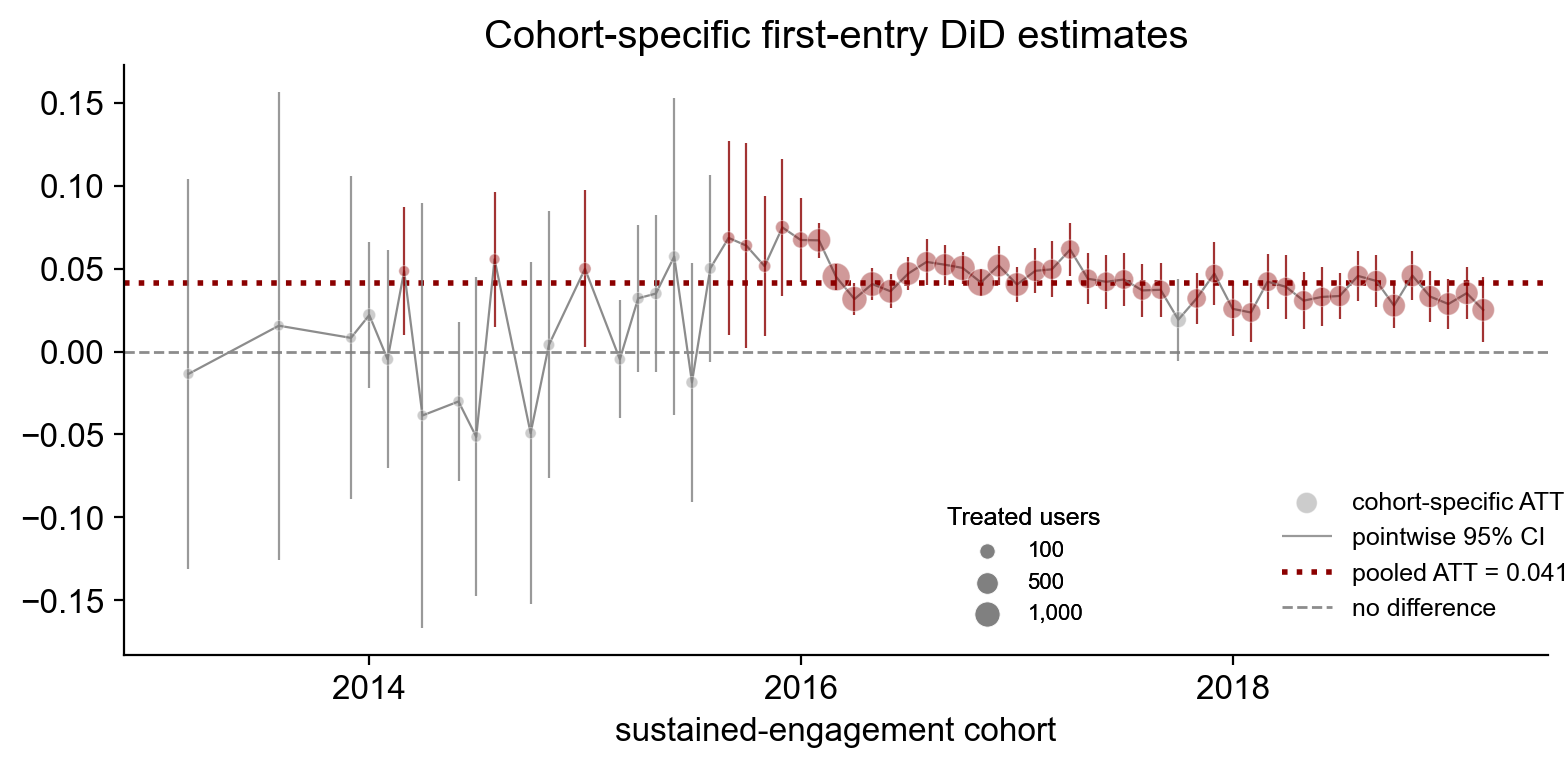

In [21]:
import matplotlib.dates as mdates

MIN_POINT_AREA = 14
MAX_POINT_AREA = 100

n_min = cohort_att_pd["n_treated"].min()
n_max = cohort_att_pd["n_treated"].max()


def treated_count_to_area(n):
    """
    Convert treated cohort size to a readable marker area.
    Square-root transformation prevents the largest cohorts from
    visually overwhelming the rest of the figure.
    """
    n = np.asarray(n, dtype=float)

    return np.interp(
        np.sqrt(n),
        [np.sqrt(n_min), np.sqrt(n_max)],
        [MIN_POINT_AREA, MAX_POINT_AREA],
    )


cohort_att_pd["point_size"] = treated_count_to_area(cohort_att_pd["n_treated"])

# pooled stacked-DiD estimate
# this should already exist from your pooled model.
pooled_att = did_result.params["treated"]

# improved cohort plot
from matplotlib.lines import Line2D
fig, ax = plt.subplots(figsize=(8, 4))

# each point represents a different treatment cohort
ax.plot(
    cohort_att_pd["cohort_month"],
    cohort_att_pd["cohort_att"],
    color="0.55",
    linewidth=0.8,
    zorder=1,
)

ci_above_zero = cohort_att_pd["ci_low"] > 0.0
estimate_colors = np.where(
    ci_above_zero,
    "darkred",   # CI entirely above zero
    "grey", # CI includes or falls below zero
)

# 95% confidence intervals
ci_artist = ax.vlines(
    x=cohort_att_pd["cohort_month"],
    ymin=cohort_att_pd["ci_low"],
    ymax=cohort_att_pd["ci_high"],
    color=estimate_colors,
    linewidth=0.8,
    alpha=0.8,
    label="pointwise 95% CI",
    zorder=2,
)

# cohort estimates: point area is proportional to n_treated
point_artist = ax.scatter(
    cohort_att_pd["cohort_month"],
    cohort_att_pd["cohort_att"],
    s=cohort_att_pd["point_size"],
    facecolor=estimate_colors,
    edgecolor="white",
    linewidth=0.4,
    label="cohort-specific ATT",
    zorder=3,
    alpha=.4,
)

# reference line: no relative change
zero_line = ax.axhline(
    0,
    color="0.55",
    linestyle="--",
    linewidth=1,
    label="no difference",
    zorder=0,
)

# pooled stacked-DiD estimate
pooled_line = ax.axhline(
    pooled_att,
    color="darkred",
    linestyle=":",
    linewidth=2,
    label=f"pooled ATT = {pooled_att:.3f}",
    zorder=0,
)

ax.set_xlabel("sustained-engagement cohort")
ax.set_title("Cohort-specific sustained-engagement DiD estimates")
# when K = 1, L = 1 --> fist-entry specification
# ax.set_xlabel("first-entry cohort")
# ax.set_ylabel("six-month DiD estimate\n(treated - not-yet-treated controls)")
ax.set_title("Cohort-specific first-entry DiD estimates")
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.spines[["top", "right"]].set_visible(False)

# legends
main_legend = ax.legend(
    handles=[point_artist, ci_artist, pooled_line, zero_line],
    loc="lower right",
    fontsize=9,
    bbox_to_anchor=(1.03, 0.02),
)
ax.add_artist(main_legend)
candidate_sizes = [100, 500, 1_000, 2_000, 3_000]
size_legend_values = [n for n in candidate_sizes if n_min <= n <= n_max]

# ensure that the observed maximum is represented when needed
if not size_legend_values:
    size_legend_values = [int(n_min), int(n_max)]


size_handles = [
    ax.scatter(
        [],
        [],
        s=treated_count_to_area(n),
        facecolor="grey",
        edgecolor="white",
        linewidth=0.3,
        label=f"{n:,}",
    )
    for n in size_legend_values
]


size_legend = ax.legend(
    handles=size_handles,
    title="Treated users",
    loc="lower right",
    fontsize=8,
    title_fontsize=9,
    frameon=False,
    bbox_to_anchor=(0.7, 0.02),
)

ax.add_artist(size_legend)

plt.tight_layout()
# plt.savefig("../../output/appendix/toxicity_cohort_estimates_staggered_did_first_entry.png", dpi=300, bbox_inches="tight")
# plt.savefig("../../output/appendix/toxicity_cohort_estimates_staggered_did_first_entry.pdf", dpi=300, bbox_inches="tight")

## Final results: add never-treated exposed users as controls

The main specification uses only later-treated users as controls. Here we broaden the control pool to also include users who are observed participating in later-banned subreddits but **never reach the \(K\)-within-$L$ sustained-engagement threshold during the 2006--2019 analysis window**.

For each focal cohort $g$, controls therefore satisfy either:

$$
G_i > g+M+L-1
$$

for later-treated users, or:

$$
G_i = \varnothing
$$

for users who never reach the sustained-engagement threshold during the observed panel.

The qualification periods, pre/post windows, treated-user definition, sample restrictions, cohort weighting, and clustered WLS estimator are otherwise unchanged. For direct comparability, the robustness analysis is restricted to the same focal treatment cohorts retained in the main specification.

`cohort_idx = null` denotes an observed never-treated user. This is an observed-panel definition rather than a claim that the user would never reach sustained engagement after 2019.


In [ ]:
# add observed never-treated exposed users to the control pool

toxicity_lf_robust = toxicity_base_all.lazy()


# Same pre/post stack assignment as the main specification.
pre_observations_robust = (
    toxicity_lf_robust
    .with_columns(
        pl.int_ranges(
            pl.col("month_idx") + QUALIFICATION_MONTHS,
            pl.col("month_idx") + QUALIFICATION_MONTHS + PRE_MONTHS,
        ).alias("stack_cohort")
    )
    .explode("stack_cohort")
    .with_columns(pl.lit("pre").alias("period"))
)

post_observations_robust = (
    toxicity_lf_robust
    .with_columns(
        pl.int_ranges(
            pl.col("month_idx") - (POST_START_LAG + POST_MONTHS - 1),
            pl.col("month_idx") - POST_START_LAG + 1,
        ).alias("stack_cohort")
    )
    .explode("stack_cohort")
    .with_columns(pl.lit("post").alias("period"))
)


stacked_observations_robust = (
    pl.concat(
        [pre_observations_robust, post_observations_robust],
        how="vertical_relaxed",
    )
    .filter(pl.col("stack_cohort").is_in(valid_cohort_ids))

    # equality is null for never-treated users, so explicitly map null -> False.
    .with_columns(
        (pl.col("cohort_idx") == pl.col("stack_cohort"))
        .fill_null(False)
        .alias("treated")
    )

    # controls may now be either:
    #   1. later-treated users whose qualification period starts after follow-up; or
    #   2. observed never-treated users (cohort_idx is null).
    .filter(
        pl.col("treated")
        | pl.col("cohort_idx").is_null()
        | (
            pl.col("cohort_idx")
            > pl.col("stack_cohort")
            + last_post_offset
            + QUALIFICATION_MONTHS
            - 1
        )
    )

    # retain control type for diagnostics only.
    .with_columns(
        pl.when(pl.col("treated"))
        .then(pl.lit("treated"))
        .when(pl.col("cohort_idx").is_null())
        .then(pl.lit("never-treated"))
        .otherwise(pl.lit("later-treated"))
        .alias("comparison_group")
    )
)


In [23]:
# user-level pre/post construction and sample restrictions

user_window_toxicity_robust = (
    stacked_observations_robust
    .group_by([
        "author", "stack_cohort", "treated",
        "comparison_group", "period",
    ])
    .agg([
        pl.col("toxicity").mean().alias("window_toxicity"),
        pl.len().alias("n_scored_submissions"),
        pl.col("month_idx").n_unique().alias("n_active_months"),
    ])
    .collect()
)


pre_window_robust = (
    user_window_toxicity_robust
    .filter(pl.col("period") == "pre")
    .select([
        "author", "stack_cohort", "treated", "comparison_group",
        pl.col("window_toxicity").alias("pre_toxicity"),
        pl.col("n_scored_submissions").alias("n_pre_submissions"),
        pl.col("n_active_months").alias("n_pre_active_months"),
    ])
)

post_window_robust = (
    user_window_toxicity_robust
    .filter(pl.col("period") == "post")
    .select([
        "author", "stack_cohort", "treated", "comparison_group",
        pl.col("window_toxicity").alias("post_toxicity"),
        pl.col("n_scored_submissions").alias("n_post_submissions"),
        pl.col("n_active_months").alias("n_post_active_months"),
    ])
)


did_pairs_robust = (
    pre_window_robust
    .join(
        post_window_robust,
        on=["author", "stack_cohort", "treated", "comparison_group"],
        how="inner",
        validate="1:1",
    )
    .filter(
        (pl.col("n_pre_submissions") >= MIN_SUBMISSIONS_PER_WINDOW)
        & (pl.col("n_post_submissions") >= MIN_SUBMISSIONS_PER_WINDOW)
        & (pl.col("n_pre_active_months") >= MIN_ACTIVE_MONTHS_PER_WINDOW)
        & (pl.col("n_post_active_months") >= MIN_ACTIVE_MONTHS_PER_WINDOW)
    )
    .with_columns(
        (pl.col("post_toxicity") - pl.col("pre_toxicity"))
        .alias("toxicity_change")
    )

    # hold the focal treatment cohorts fixed to those
    # retained in the main later-treated-only specification.
    .filter(
        pl.col("stack_cohort").is_in(
            cohort_counts.get_column("stack_cohort").to_list()
        )
    )
)


In [24]:
# cohort-size restrictions and weighting

cohort_counts_robust = (
    did_pairs_robust
    .group_by("stack_cohort")
    .agg([
        pl.col("author").filter(pl.col("treated")).n_unique().alias("n_treated"),
        pl.col("author").filter(~pl.col("treated")).n_unique().alias("n_controls"),
    ])
    .filter(
        (pl.col("n_treated") >= MIN_TREATED_PER_COHORT)
        & (pl.col("n_controls") >= MIN_CONTROLS_PER_COHORT)
    )
)


did_pairs_robust = (
    did_pairs_robust
    .join(
        cohort_counts_robust,
        on="stack_cohort",
        how="inner",
        validate="m:1",
    )
    .with_columns([
        pl.when(pl.col("treated"))
        .then(pl.lit(1.0))
        .otherwise(pl.col("n_treated") / pl.col("n_controls"))
        .alias("stack_weight"),
        pl.col("treated").cast(pl.Int8),
    ])
)


print("Usable treatment cohorts:", cohort_counts_robust.height)
print("Rows in robustness DiD sample:", f"{did_pairs_robust.height:,}")
print(
    "Unique treated users:",
    did_pairs_robust.filter(pl.col("treated") == 1)["author"].n_unique(),
)
print(
    "Unique later-treated controls:",
    did_pairs_robust
    .filter(pl.col("comparison_group") == "later-treated")["author"]
    .n_unique(),
)
print(
    "Unique never-treated controls:",
    did_pairs_robust
    .filter(pl.col("comparison_group") == "never-treated")["author"]
    .n_unique(),
)


Usable treatment cohorts: 62
Rows in robustness DiD sample: 2,123,331
Unique treated users: 20658
Unique later-treated controls: 23708
Unique never-treated controls: 123000


In [25]:
# stacked DiD with later-treated + never-treated controls

did_pd_robust = did_pairs_robust.to_pandas()
did_pd_robust["stack_cohort"] = did_pd_robust["stack_cohort"].astype("category")
did_pd_robust["treated"] = did_pd_robust["treated"].astype(int)

did_model_robust = smf.wls(
    formula=("toxicity_change ~ treated + C(stack_cohort)"),
    data=did_pd_robust,
    weights=did_pd_robust["stack_weight"],
)

did_result_robust = did_model_robust.fit(
    cov_type="cluster",
    cov_kwds={
        "groups": did_pd_robust["author"],
        "use_correction": True,
    },
)


robust_att = did_result_robust.params["treated"]
robust_se = did_result_robust.bse["treated"]
robust_ci_low, robust_ci_high = did_result_robust.conf_int().loc["treated"]
robust_p_value = did_result_robust.pvalues["treated"]

print(did_result_robust.summary().tables[1])
print()
print(f"Robustness ATT: {robust_att:.4f}")
print(f"Clustered SE: {robust_se:.4f}")
print(f"95% CI: [{robust_ci_low:.4f}, {robust_ci_high:.4f}]")
print(f"p-value: {robust_p_value:.4g}")


                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept                   -0.0350      0.026     -1.350      0.177      -0.086       0.016
C(stack_cohort)[T.24163]     0.0073      0.039      0.185      0.853      -0.070       0.085
C(stack_cohort)[T.24167]     0.0073      0.033      0.218      0.827      -0.058       0.073
C(stack_cohort)[T.24168]     0.0170      0.028      0.604      0.546      -0.038       0.072
C(stack_cohort)[T.24169]     0.0067      0.030      0.221      0.825      -0.053       0.066
C(stack_cohort)[T.24170]     0.0359      0.027      1.315      0.189      -0.018       0.089
C(stack_cohort)[T.24171]    -0.0053      0.038     -0.139      0.890      -0.080       0.070
C(stack_cohort)[T.24173]     0.0032      0.028      0.114      0.910      -0.053       0.059
C(stack_cohort)[T.24174]    -0.0055      0.034     -0.164      0.870  

In [26]:
# ============================================================
# Main vs robustness comparison
# ============================================================

main_ci_low, main_ci_high = did_result.conf_int().loc["treated"]

specification_comparison = pd.DataFrame({
    "specification": [
        "Main: later-treated controls",
        "Robustness: later-treated + never-treated controls",
    ],
    "att": [
        did_result.params["treated"],
        did_result_robust.params["treated"],
    ],
    "se": [
        did_result.bse["treated"],
        did_result_robust.bse["treated"],
    ],
    "ci_low": [
        main_ci_low,
        robust_ci_low,
    ],
    "ci_high": [
        main_ci_high,
        robust_ci_high,
    ],
    "p_value": [
        did_result.pvalues["treated"],
        did_result_robust.pvalues["treated"],
    ],
})

specification_comparison


,specification,att,se,ci_low,ci_high,p_value
0,Main: later-treated controls,0.041067,0.001288,0.038543,0.043592,4.712556e-223
1,Robustness: later-treated + never-treated cont...,0.046325,0.001003,0.044360,0.048290,0.000000e+00


In [ ]:

# cohort-specific ATT
# same cohort-specific estimand as the main analysis,
# but controls = later-treated + never-treated exposed users.

cohort_att_robust = (
    did_pairs_robust
    .group_by("stack_cohort")
    .agg([
        # Treated users' average pre/post change
        pl.col("toxicity_change")
        .filter(pl.col("treated") == 1)
        .mean()
        .alias("treated_change"),

        # Sample variance of treated users' changes
        pl.col("toxicity_change")
        .filter(pl.col("treated") == 1)
        .var()
        .alias("treated_var"),

        # ROBUSTNESS:
        # Combined control mean across later-treated + never-treated users
        pl.col("toxicity_change")
        .filter(pl.col("treated") == 0)
        .mean()
        .alias("control_change"),

        # Sample variance of the combined robustness control group
        pl.col("toxicity_change")
        .filter(pl.col("treated") == 0)
        .var()
        .alias("control_var"),

        pl.col("n_treated").first(),
        pl.col("n_controls").first(),
    ])
    .with_columns(
        (
            pl.col("treated_change")
            - pl.col("control_change")
        ).alias("cohort_att")
    )
    .sort("stack_cohort")
)


# ------------------------------------------------------------
# Pointwise 95% CIs, matching the main cohort-specific analysis
# ------------------------------------------------------------

cohort_att_robust_pd = cohort_att_robust.to_pandas()

cohort_att_robust_pd["treated_mean_var"] = (
    cohort_att_robust_pd["treated_var"]
    / cohort_att_robust_pd["n_treated"]
)

cohort_att_robust_pd["control_mean_var"] = (
    cohort_att_robust_pd["control_var"]
    / cohort_att_robust_pd["n_controls"]
)

cohort_att_robust_pd["cohort_se"] = np.sqrt(
    cohort_att_robust_pd["treated_mean_var"]
    + cohort_att_robust_pd["control_mean_var"]
)

cohort_att_robust_pd["welch_df"] = (
    (cohort_att_robust_pd["treated_mean_var"]
        + cohort_att_robust_pd["control_mean_var"]
    ) ** 2
    /
    (
        (cohort_att_robust_pd["treated_mean_var"] ** 2)
        / (cohort_att_robust_pd["n_treated"] - 1) +
        (cohort_att_robust_pd["control_mean_var"] ** 2)
        / (cohort_att_robust_pd["n_controls"] - 1)
    )
)

cohort_att_robust_pd["t_critical"] = t_dist.ppf(
    0.975,
    df=cohort_att_robust_pd["welch_df"],
)

cohort_att_robust_pd["ci_low"] = (
    cohort_att_robust_pd["cohort_att"]
    - cohort_att_robust_pd["t_critical"]
    * cohort_att_robust_pd["cohort_se"]
)

cohort_att_robust_pd["ci_high"] = (
    cohort_att_robust_pd["cohort_att"]
    + cohort_att_robust_pd["t_critical"]
    * cohort_att_robust_pd["cohort_se"]
)


# Convert cohort index back to calendar month
cohort_att_robust_pd["cohort_year"] = (
    cohort_att_robust_pd["stack_cohort"] // 12
)

cohort_att_robust_pd["cohort_month_number"] = (
    cohort_att_robust_pd["stack_cohort"] % 12 + 1
)

cohort_att_robust_pd["cohort_month"] = pd.to_datetime({
    "year": cohort_att_robust_pd["cohort_year"],
    "month": cohort_att_robust_pd["cohort_month_number"],
    "day": 1,
})

# Use the SAME treated-user marker-size mapping as the main plot.
# Because focal treatment cohorts are held fixed, this keeps the
# two cohort plots directly visually comparable.
cohort_att_robust_pd["point_size"] = treated_count_to_area(
    cohort_att_robust_pd["n_treated"]
)

cohort_att_robust_pd.head()


,stack_cohort,treated_change,treated_var,control_change,control_var,n_treated,n_controls,cohort_att,treated_mean_var,control_mean_var,cohort_se,welch_df,t_critical,ci_low,ci_high,cohort_year,cohort_month_number,cohort_month,point_size
0,24158,-0.018441,0.034313,-0.005294,0.014401,12,11774,-0.013146,0.002859,1.223127e-06,0.053485,11.009413,2.200756,-0.130854,0.104561,2013,3,2013-03-01,14.725848
1,24163,0.001671,0.038909,-0.010829,0.014310,10,14269,0.012500,0.003891,1.002892e-06,0.062385,9.004640,2.261979,-0.128614,0.153613,2013,8,2013-08-01,14.000000
2,24167,-0.000240,0.020987,-0.008909,0.014256,11,16454,0.008669,0.001908,8.664245e-07,0.043689,10.009085,2.227865,-0.088664,0.106003,2013,12,2013-12-01,14.371185
3,24168,0.016503,0.017998,-0.006269,0.014024,38,16891,0.022772,0.000474,8.302407e-07,0.021782,37.129833,2.025953,-0.021357,0.066901,2014,1,2014-01-01,21.219757
4,24169,-0.006275,0.024124,-0.004065,0.013880,24,17495,-0.002209,0.001005,7.933493e-07,0.031717,23.036320,2.068477,-0.067815,0.063397,2014,2,2014-02-01,18.176547


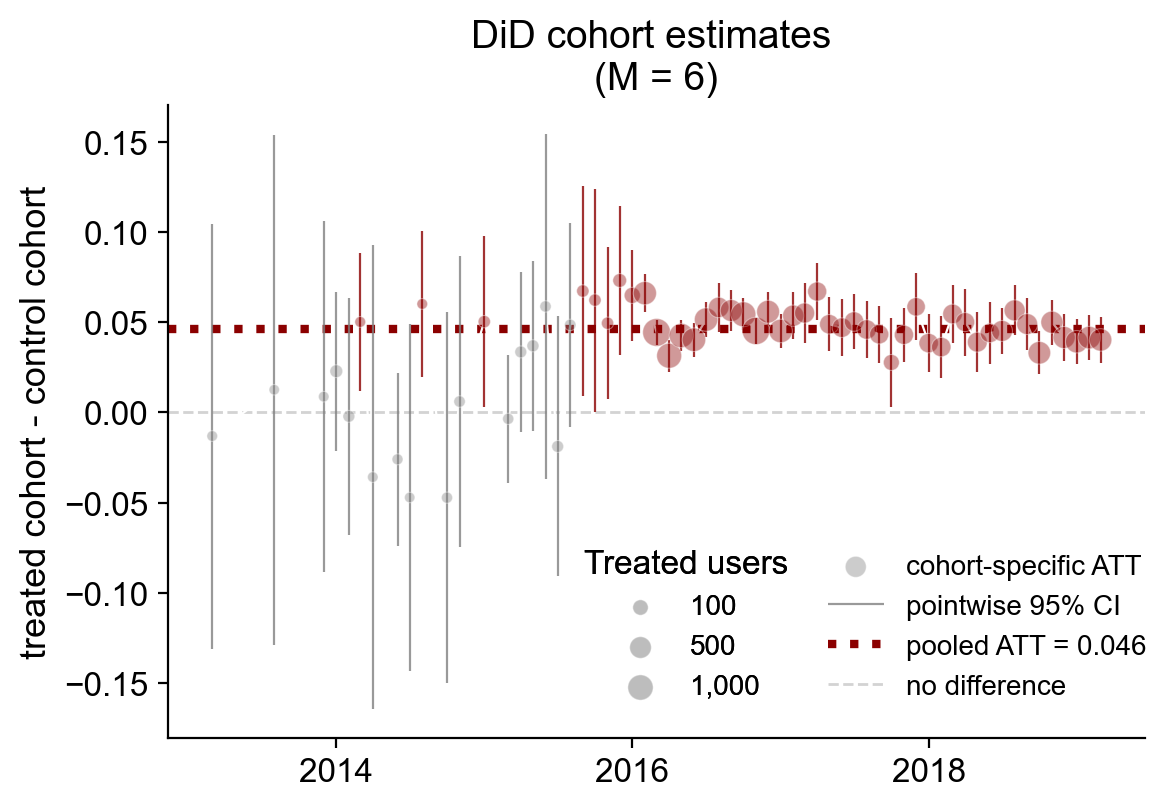

In [28]:
fig, ax = plt.subplots(figsize=(6, 4.2))

ax.plot(
    cohort_att_robust_pd["cohort_month"],
    cohort_att_robust_pd["cohort_att"],
    color="white",
    linewidth=0.8,
    zorder=1,
)

ci_above_zero = cohort_att_robust_pd["ci_low"] > 0.0

estimate_colors = np.where(
    ci_above_zero,
    "darkred",   # CI entirely above zero
    "grey", # CI includes or falls below zero
)

# pointwise 95% confidence intervals
ci_artist_robust = ax.vlines(
    x=cohort_att_robust_pd["cohort_month"],
    ymin=cohort_att_robust_pd["ci_low"],
    ymax=cohort_att_robust_pd["ci_high"],
    color=estimate_colors,
    linewidth=0.8,
    alpha=0.8,
    label="pointwise 95% CI",
    zorder=2,
)

# cohort-specific robustness estimates
point_artist_robust = ax.scatter(
    cohort_att_robust_pd["cohort_month"],
    cohort_att_robust_pd["cohort_att"],
    s=cohort_att_robust_pd["point_size"],
    facecolor=estimate_colors,
    edgecolor="white",
    linewidth=0.4,
    label="cohort-specific ATT",
    zorder=3,
    alpha=.4,
)

# no-difference reference line
zero_line_robust = ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
    color="lightgrey",
    label="no difference",
    zorder=0,
)

# pooled ATT from the robustness WLS model
pooled_line_robust = ax.axhline(
    robust_att,
    color="darkred",
    linestyle=":",
    linewidth=3,
    label=f"pooled ATT = {robust_att:.3f}",
    zorder=0,
)


# Labels and formatting
# ax.set_xlabel("sustained-engagement cohort")

ax.set_ylabel("treated cohort - control cohort", fontsize=13)
# ax.set_title("DiD cohort estimates", fontsize=14)
ax.set_title(f"DiD cohort estimates \n(M = {PRE_MONTHS})", fontsize=14)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.spines[["top", "right"]].set_visible(False)


# Main legend
main_legend_robust = ax.legend(
    handles=[
        point_artist_robust,
        ci_artist_robust,
        pooled_line_robust,
        zero_line_robust,
    ],
    loc="lower left",
    bbox_to_anchor=(0.65, 0.02),
    fontsize=10,
)

ax.add_artist(main_legend_robust)


# Marker-size legend: same scale as main plot
size_handles_robust = [
    ax.scatter(
        [],
        [],
        s=treated_count_to_area(n),
        facecolor="grey",
        edgecolor="white",
        linewidth=0.4,
        alpha=.3,
        label=f"{n:,}",
    )
    for n in size_legend_values
]

size_legend_robust = ax.legend(
    handles=size_handles_robust,
    title="Treated users",
    loc="lower left",
    bbox_to_anchor=(0.4, 0.02),
    fontsize=10,
    title_fontsize=12,
    frameon=False,
)

ax.add_artist(size_legend_robust)

plt.tight_layout()

# plt.savefig("../../output/mainbody/toxicity_cohort_estimates_staggered_did_sustained_engagement.png", dpi=300, bbox_inches="tight")
# plt.savefig("../../output/mainbody/toxicity_cohort_estimates_staggered_did_sustained_engagement.pdf", dpi=300, bbox_inches="tight")
# plt.savefig("../../output/appendix/toxicity_cohort_estimates_staggered_did_sustained_engagement_robustness_M9.png", dpi=300, bbox_inches="tight")
# plt.savefig("../../output/appendix/toxicity_cohort_estimates_staggered_did_sustained_engagement_robustness_M9.pdf", dpi=300, bbox_inches="tight")